# 04 · Correlation — Gast↔pSom cross-repression at the convergence hub (Gate 3)

Gate 3 (branching): do the **convergence-hub** node-clusters show mutual Gast↔pSom **negative**
correlation (competitive cross-repression)? We (1) show the **per-arm identity table** — the decisive
read — and (2) compute the reference per-gene mutual correlation on the geodesic neighbourhood of the
topological convergence hub, rendered as the Spectral correlation map.

**Result: Gate 3 = NO-GO.** After scoping, **every arm is pSom-positive and Gast-flat** (no Gast-arm
vs pSom-arm split); arms differ in **Crest** (two Crest-terminal arms). The tree separates
Crest-terminal differentiation states, not a Gast↔pSom axis. Hub per-gene r is weakly positive/near
zero, far from the Puram hub (-0.49).

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd, scanpy as sc, matplotlib.pyplot as plt
import scipy.sparse as sp, networkx as nx
from scipy.sparse.csgraph import shortest_path
from scipy.stats import pearsonr
sc.settings.verbosity = 1; SEED = 1

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars'); pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
B = np.asarray(adata.uns['graph']['B']); deg=(B>0).sum(0)
tips = np.where(deg==1)[0]; forks = np.where(deg>=3)[0]
root = int(adata.uns['root_node']); hub = int(adata.uns['hub_node'])
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
print('tips', tips.tolist(), '| forks', forks.tolist(), '| root', root, '| convergence hub', hub)

tips [14, 53, 96, 98, 183] | forks [93, 127, 134] | root 53 | convergence hub 127


### Per-arm identity (cells assigned to nearest tip) — the decisive Gate-3 read

In [4]:
tip_of = np.array([tips[np.argmin(D[hard[i], tips])] for i in range(adata.n_obs)])
rows=[]
for t in tips:
    m = tip_of==t
    if m.sum() < 10: continue
    rows.append((int(t), int(m.sum()), round(adata.obs.Gast_sm[m].mean(),3),
                 round(adata.obs.pSom_sm[m].mean(),3), round(adata.obs.Crest_sm[m].mean(),3),
                 round(adata.obs.t[m].mean(),1)))
arm = pd.DataFrame(rows, columns=['tip','n','Gast_sm','pSom_sm','Crest_sm','pt']).sort_values('Crest_sm')
print(arm.to_string(index=False))
print(f'\nGast_sm across arms: [{arm.Gast_sm.min():+.3f}, {arm.Gast_sm.max():+.3f}]  (flat -> no Gast-arm)')
print(f'pSom_sm across arms: [{arm.pSom_sm.min():+.3f}, {arm.pSom_sm.max():+.3f}]  (all positive: {bool((arm.pSom_sm>0).all())})')
print(f'Crest_sm across arms: [{arm.Crest_sm.min():+.3f}, {arm.Crest_sm.max():+.3f}]  (arms differ in Crest -> Crest-terminal split)')
crest_arms = arm[arm.Crest_sm >= arm.Crest_sm.quantile(0.6)].tip.tolist()
print('Crest-terminal arm tips:', crest_arms)

 tip   n  Gast_sm  pSom_sm  Crest_sm    pt
  53 334    0.050    0.235     0.021   6.5
  96 484    0.030    0.250     0.052  35.5
  14 264    0.044    0.190     0.070 120.1
 183 573    0.005    0.214     0.143  66.6
  98 312   -0.077    0.122     0.241  94.1

Gast_sm across arms: [-0.077, +0.050]  (flat -> no Gast-arm)
pSom_sm across arms: [+0.122, +0.250]  (all positive: True)
Crest_sm across arms: [+0.021, +0.241]  (arms differ in Crest -> Crest-terminal split)
Crest-terminal arm tips: [183, 98]


### Reference per-gene mutual correlation on the convergence-hub cells

In [5]:
get = lambda p: set(pd.read_csv(p).hsapiens)
gast = get(os.path.join(pth_feat,'GSE162534.csv')); psom = get(os.path.join(pth_feat,'GSE229103.csv'))
gx = pd.Series(list(gast ^ psom)); gx = gx.loc[gx.isin(adata.var_names)]
res={}
for rad in [3,4,5]:
    m = np.isin(hard, np.where(D[hub]<=rad)[0]); sub = adata[m, gx.values]
    X = pd.DataFrame(sub.X.toarray(), columns=gx); X = X.loc[:, X.nunique(0)>1]
    a = pearsonr(X, sub.obs.Gast.values[:,None], axis=0).statistic
    b = pearsonr(X, sub.obs.pSom.values[:,None], axis=0).statistic
    res[rad] = (np.corrcoef(a,b)[0,1], int(m.sum()))
    print(f'hub geodesic<= {rad}: mutual Gast<->pSom r = {res[rad][0]:+.3f}  (n={res[rad][1]})')
hub_r = res[5][0]
print(f'\nGate 3: hub per-gene r = {hub_r:+.3f} (geodesic<=5); weakly positive/near-zero, far from Puram -0.49 -> NO-GO')
# windowed correlation for the map (over hub cells, along pseudotime)
mh = np.isin(hard, np.where(D[hub]<=5)[0]); adc = adata[mh, gx.values].copy()
tb = pd.cut(adc.obs.t, bins=max(2, adc.n_obs//60)); adc.obs['tb']=tb; rr={}
for bb,sdf in adc.obs.groupby('tb', observed=True):
    ab=adc[sdf.index]; X=pd.DataFrame(ab.X.toarray(),columns=gx); X=X.loc[:,X.nunique(0)>1]
    a=pearsonr(X,sdf.Gast.values[:,None],axis=0).statistic; b=pearsonr(X,sdf.pSom.values[:,None],axis=0).statistic
    rr[bb]=np.corrcoef(a,b)[0,1]
Adj=adc.obsp['connectivities']; Rs=tb.map(rr).astype(float)
adc.obs['correlation']=(Adj@Rs)/np.asarray(Adj.sum(1)).ravel()

hub geodesic<= 3: mutual Gast<->pSom r = +0.279  (n=25)
hub geodesic<= 4: mutual Gast<->pSom r = +0.303  (n=37)
hub geodesic<= 5: mutual Gast<->pSom r = +0.255  (n=49)

Gate 3: hub per-gene r = +0.255 (geodesic<=5); weakly positive/near-zero, far from Puram -0.49 -> NO-GO


### Convergence-hub module correlation map (`correlation.pdf`) + R_colorbar

saved correlation.pdf + R_colorbar.pdf | Gate 3 NO-GO (Crest-terminal split, not Gast<->pSom)


<ipython-input-6-a96585fe62bd>:12: UserWarning: Adding colorbar to a different Figure <Figure size 500x500 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[1], cax=cax); cb.ax.tick_params(which='both',size=0)


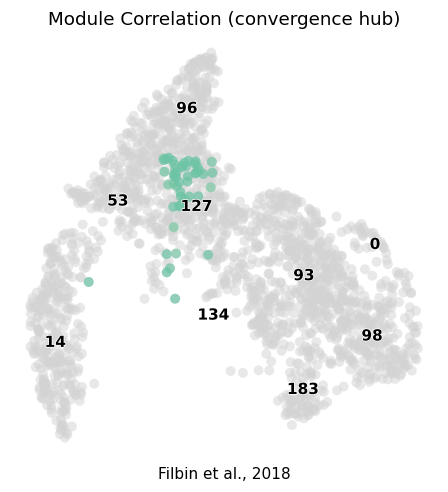

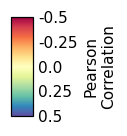

In [6]:
vlim=.5
fig, ax = plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(adata, size=170, alpha=.5, frameon=False, show=False, ax=ax)
sc.pl.umap(adc, color='correlation', cmap='Spectral', vmin=-vlim, vmax=vlim, size=170, alpha=.7,
           colorbar_loc=None, frameon=False, show=False, ax=ax)
sc.pl.umap(adata, color='milestones', size=170, alpha=0, legend_loc='on data',
           legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis(); ax.set_title('Module Correlation (convergence hub)', size=12)
ax.text(.5,-.05,'Filbin et al., 2018', ha='center', transform=ax.transAxes)
fig.savefig(os.path.join(pth_fig,'correlation.pdf'), bbox_inches='tight'); plt.show()
fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
cb = plt.colorbar(ax.collections[1], cax=cax); cb.ax.tick_params(which='both',size=0)
cb.set_label('Pearson\nCorrelation'); cb.ax.invert_yaxis()
ticks=np.asarray([-.5,-.25,0,.25,.5]); cb.set_ticks(ticks,labels=ticks); cb.solids.set_alpha(1)
fcb.savefig(os.path.join(pth_cb,'R_colorbar.pdf'), bbox_inches='tight'); plt.show()
print('saved correlation.pdf + R_colorbar.pdf | Gate 3 NO-GO (Crest-terminal split, not Gast<->pSom)')